# MLEs, Linear Regression and Learning Theory

# Table of Contents

### 1. Maximum Likelihood Estimation (MLE)
* **1.1** The Core Task: Fitting Models to Data
* **1.2** The MLE Principle
* **1.3** The Log-Likelihood Trick
* **1.4** Example 1: The Biased Coin (Bernoulli)
* **1.5** Example 2: The Univariate Gaussian
* **1.6** Checking the MLEs in Python

### 2. Linear Regression
* **2.1** The Model
* **2.2** Finding $w$ via MLE
* **2.3** MLE and Least Squares
* **2.4** The Normal Equations
* **2.5** Solving OLS in Python
* **2.6** A Critical Problem of the OLS Solution

### 3. Regularization
* **3.1** Ridge Regression (L2)
* **3.2** Formalising Regularization
* **3.3** Lasso Regression (L1)
* **3.4** Solving Ridge and Lasso in Python

### 4. The Bayesian View of Regularization
* **4.1** MAP Estimation
* **4.2** MAP with a Gaussian Prior is Ridge
* **4.3** MAP with a Laplace Prior is Lasso

### 5. Why Does Lasso Create Sparsity?
* **5.1** Explanation 1: The Laplace Prior
* **5.2** Explanation 2: Soft Thresholding
* **5.3** Explanation 3: The Geometric View
* **5.4** A Practical Note: Optimization
* **5.5** Summary

### 6. Model Selection with Cross-Validation
* **6.1** The Hyperparameter Problem
* **6.2** K-Fold Cross-Validation
* **6.3** The Full Workflow for Model Selection
* **6.4** Polynomial Regression and Overfitting
* **6.5** Choosing $\lambda$ with Cross-Validation in Python

### 7. Bias-Variance Tradeoff
* **7.1** Decomposition of Prediction Error
* **7.2** What is Bias and Variance?
* **7.3** The Tradeoff with Model Complexity
* **7.4** Summary

 # ------------------------------------------------------------------------------

# 1. Maximum Likelihood Estimation (MLE)

## 1.1 The Core Task: Fitting Models to Data

In [1]:
# imports init
import numpy as np
import matplotlib.pyplot as plt

We observe some data $D$, and we assume it was generated by a probabilistic model $p(D|\theta)$ with unknown parameters $\theta$. For example:
* We observe the heights of 100 people. We might assume the data comes from a Gaussian distribution $\mathcal{N}(\mu,\sigma^2)$, so the parameters to estimate are $\theta = (\mu,\sigma^2)$.
* We flip a coin 100 times and observe 60 heads. We might assume the data comes from a Bernoulli distribution with parameter $\phi$, so the parameter to estimate is $\theta = (\phi)$.

The fundamental question is: how do we choose the "best" parameters $\theta$ to explain the data we saw?

## 1.2 The MLE Principle

The MLE principle is to find the parameters $\theta$ that make the observed data $D$ most probable. We define the **likelihood** of the parameters $\theta$ as the probability of the data given those parameters:
$$
L(\theta;D) = p(D|\theta)
$$
If the data points $D = \{x_1,\dots,x_N\}$ are independent and identically distributed (i.i.d.), the likelihood is the product of the individual probabilities:
$$
L(\theta;D) = \prod_{i=1}^{N} p(x_i|\theta)
$$
Our goal is to find the parameters that maximise this function:
$$
\hat{\theta}_{MLE} = \arg\max_{\theta} L(\theta;D)
$$

## 1.3 The Log-Likelihood Trick

Working with products is hard, the derivatives are messy and the product of many small probabilities can lead to numerical underflow. So instead we maximise the **log-likelihood**. Since $\log$ is a monotonically increasing function, this doesn't change where the maximum occurs.
$$
\mathcal{L}(\theta) = \log p(D|\theta) = \sum_{i=1}^{N} \log p(x_i|\theta)
$$
This turns the difficult product into a friendlier sum. We find the MLE by solving:
$$
\hat{\theta}_{MLE} = \arg\max_{\theta} \mathcal{L}(\theta) = \arg\min_{\theta} -\mathcal{L}(\theta)
$$
This is typically done by setting the derivative $\frac{d\mathcal{L}}{d\theta}$ to zero, or by gradient descent.

## 1.4 Example 1: The Biased Coin (Bernoulli)

We toss a coin $N$ times. Let $N_H$ be the number of heads and $N_T$ be the number of tails, and let $\phi$ be the unknown probability of heads. We want to find the MLE for $\phi$.

The likelihood of a single toss is $p(x|\phi) = \phi^x(1-\phi)^{1-x}$, where $x=1$ for heads and $x=0$ for tails. So the likelihood and log-likelihood of the entire sequence of tosses is:
$$
\begin{align*}
L(\phi) &= p(D|\phi) = \phi^{N_H}(1-\phi)^{N_T} \\
\mathcal{L}(\phi) &= \log L(\phi) = N_H\log\phi + N_T\log(1-\phi)
\end{align*}
$$

Taking the derivative w.r.t. $\phi$ and setting it to $0$:
$$
\begin{align*}
\frac{d\mathcal{L}}{d\phi} &= \frac{N_H}{\phi} - \frac{N_T}{1-\phi} = 0 \\
&\implies N_H(1-\phi) = N_T\phi \\
&\implies N_H = (N_H + N_T)\phi
\end{align*}
$$
Therefore:
$$
\hat{\phi}_{MLE} = \frac{N_H}{N_H + N_T} = \frac{\text{Number of Heads}}{\text{Total Tosses}}
$$
The MLE result is exactly what our intuition tells us!

## 1.5 Example 2: The Univariate Gaussian

Suppose we have i.i.d. data $D = \{x_1,\dots,x_N\}$ drawn from a Gaussian distribution $\mathcal{N}(\mu,\sigma^2)$. Our parameters are $\theta = (\mu,\sigma^2)$ and we want to find the MLE for both $\mu$ and $\sigma^2$.

The PDF for a single data point is:
$$
p(x_i|\mu,\sigma^2) = \frac{1}{\sqrt{2\pi\sigma^2}}\exp\left(-\frac{(x_i-\mu)^2}{2\sigma^2}\right)
$$
So the log-likelihood for the entire dataset is:
$$
\begin{align*}
\mathcal{L}(\mu,\sigma^2) &= \sum_{i=1}^{N}\log p(x_i|\mu,\sigma^2) \\
&= \sum_{i=1}^{N}\left[-\frac{1}{2}\log(2\pi\sigma^2) - \frac{(x_i-\mu)^2}{2\sigma^2}\right] \\
&= -\frac{N}{2}\log(2\pi) - \frac{N}{2}\log(\sigma^2) - \frac{1}{2\sigma^2}\sum_{i=1}^{N}(x_i-\mu)^2
\end{align*}
$$
Now we find the parameters that maximise this function.

### Solving for the Mean $\mu$
We take the partial derivative of $\mathcal{L}$ with respect to $\mu$ and set it to zero, treating $\sigma^2$ as a constant.
$$
\begin{align*}
\frac{\partial\mathcal{L}}{\partial\mu} &= \frac{\partial}{\partial\mu}\left[-\frac{N}{2}\log(2\pi) - \frac{N}{2}\log(\sigma^2) - \frac{1}{2\sigma^2}\sum_{i=1}^{N}(x_i-\mu)^2\right] \\
&= -\frac{1}{2\sigma^2}\sum_{i=1}^{N}2(x_i-\mu)(-1) = \frac{1}{\sigma^2}\sum_{i=1}^{N}(x_i-\mu)
\end{align*}
$$
Setting the derivative to zero:
$$
\begin{align*}
\frac{1}{\sigma^2}\sum_{i=1}^{N}(x_i-\mu) = 0 &\implies \sum_{i=1}^{N}x_i - \sum_{i=1}^{N}\mu = 0 \\
&\implies \sum_{i=1}^{N}x_i - N\mu = 0 \\
&\implies \hat{\mu}_{MLE} = \frac{1}{N}\sum_{i=1}^{N}x_i
\end{align*}
$$
The MLE for the mean is simply the **sample mean**.

### Solving for the Variance $\sigma^2$
Now we take the partial derivative of $\mathcal{L}$ with respect to $\sigma^2$ and set it to zero, treating $\mu$ as a constant (we plug in $\hat{\mu}_{MLE}$ later).
$$
\begin{align*}
\frac{\partial\mathcal{L}}{\partial\sigma^2} &= \frac{\partial}{\partial\sigma^2}\left[C - \frac{N}{2}\log(\sigma^2) - \frac{1}{2\sigma^2}\sum_{i=1}^{N}(x_i-\mu)^2\right] \\
&= -\frac{N}{2}\frac{1}{\sigma^2} + \frac{1}{2(\sigma^2)^2}\sum_{i=1}^{N}(x_i-\mu)^2
\end{align*}
$$
Setting the derivative to zero and plugging in $\hat{\mu}_{MLE}$ for $\mu$:
$$
\begin{align*}
\frac{1}{2(\sigma^2)^2}\sum_{i=1}^{N}(x_i-\hat{\mu}_{MLE})^2 &= \frac{N}{2\sigma^2} \\
\frac{1}{\sigma^2}\sum_{i=1}^{N}(x_i-\hat{\mu}_{MLE})^2 &= N \\
\implies \hat{\sigma}^2_{MLE} &= \frac{1}{N}\sum_{i=1}^{N}(x_i-\hat{\mu}_{MLE})^2
\end{align*}
$$
The MLE for the variance is the **sample variance** (note: we divide by $N$, not $N-1$).

## 1.6 Checking the MLEs in Python

We can check both results numerically, by simulating some data and comparing the closed-form MLEs with the maximum of the log-likelihood.

In [2]:
# first we fix the random seed so the results are reproducible
rng = np.random.default_rng(0)

# --- Bernoulli ---
# we flip a biased coin 100 times, the true probability of heads is 0.6
true_phi = 0.6
flips = rng.binomial(1, true_phi, size=100)
N_H = flips.sum()
N_T = len(flips) - N_H

# closed form MLE
phi_mle = N_H / (N_H + N_T)

# next we evaluate the log-likelihood on a grid of phi values to check the maximum is in the same place
phi_grid = np.linspace(0.01, 0.99, 999)
log_lik = N_H*np.log(phi_grid) + N_T*np.log(1 - phi_grid)

print("--- Bernoulli MLE ---")
print(f"N_H = {N_H}, N_T = {N_T}")
print(f"Closed form phi_MLE      = {phi_mle:.3f}")
print(f"Grid search maximum at   = {phi_grid[np.argmax(log_lik)]:.3f}\n")

# --- Gaussian ---
# we observe the heights (cm) of 100 people
heights = rng.normal(loc=170, scale=8, size=100)
mu_mle = heights.sum() / len(heights)
sigma2_mle = ((heights - mu_mle)**2).sum() / len(heights)

print("--- Gaussian MLE ---")
print(f"mu_MLE      = {mu_mle:.3f}   (np.mean          = {np.mean(heights):.3f})")
print(f"sigma2_MLE  = {sigma2_mle:.3f}  (np.var, ddof = 0 = {np.var(heights):.3f})")

--- Bernoulli MLE ---
N_H = 51, N_T = 49
Closed form phi_MLE      = 0.510
Grid search maximum at   = 0.510

--- Gaussian MLE ---
mu_MLE      = 169.367   (np.mean          = 169.367)
sigma2_MLE  = 60.264  (np.var, ddof = 0 = 60.264)


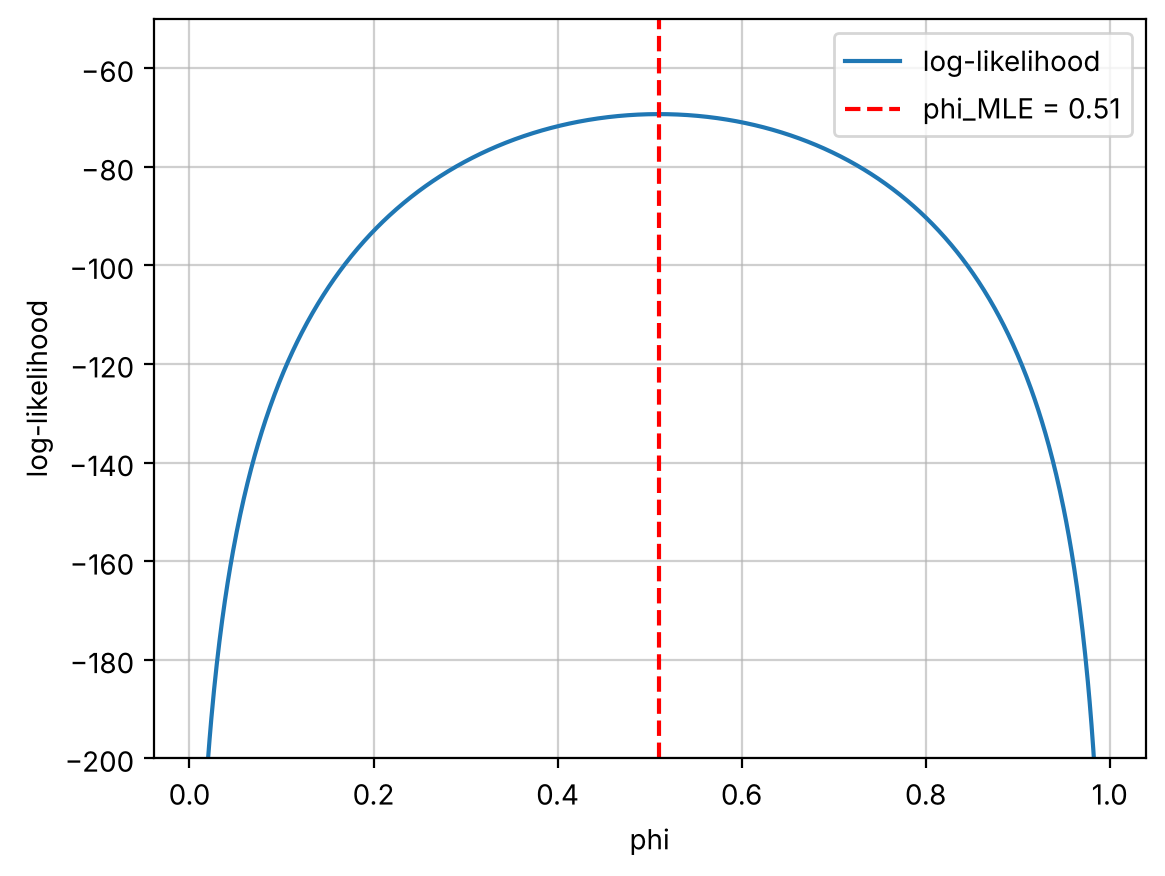

In [3]:
# plot of the Bernoulli log-likelihood
plt.plot(phi_grid, log_lik, label="log-likelihood")
plt.axvline(x=phi_mle, color="red", linestyle="--", label=f"phi_MLE = {phi_mle:.2f}")
plt.xlabel("phi")
plt.ylabel("log-likelihood")
plt.ylim(-200, -50)
plt.legend()
plt.grid(True, alpha=0.6)

# 2. Linear Regression

So far we have used a general principle (MLE) to estimate the parameters of simple probability distributions (Bernoulli, Gaussian). We now apply the exact same principle to find the parameters of a machine learning model. To do this we need a probabilistic model that connects our inputs $x$, outputs $y$, and weights $w$.

## 2.1 The Model

We assume the output $y$ is a linear function of the inputs $x$, plus Gaussian noise $\epsilon$:
$$
y_i = w^Tx_i + \epsilon_i
$$
where the feature vector is $x_i \in \mathbb{R}^D$ and the weights are $w \in \mathbb{R}^D$. We model the noise as being drawn from a zero-mean Normal distribution:
$$
\epsilon_i \sim \mathcal{N}(0,\sigma^2)
$$
This implies a conditional probability distribution for $y_i$:
$$
p(y_i|x_i,w,\sigma^2) = \mathcal{N}(y_i|w^Tx_i,\sigma^2)
$$
This is our model's "probabilistic prediction". The parameters to learn are $\theta = \{w,\sigma^2\}$.

## 2.2 Finding $w$ via MLE

First we write down the log-likelihood:
$$
\begin{align*}
\mathcal{L}(w,\sigma^2) &= \sum_{i=1}^{N}\log\left[\frac{1}{\sqrt{2\pi\sigma^2}}\exp\left(-\frac{(y_i - w^Tx_i)^2}{2\sigma^2}\right)\right] \\
&= \sum_{i=1}^{N}\left[-\frac{1}{2}\log(2\pi\sigma^2) - \frac{1}{2\sigma^2}(y_i - w^Tx_i)^2\right] \\
&= -\frac{N}{2}\log(2\pi\sigma^2) - \frac{1}{2\sigma^2}\sum_{i=1}^{N}(y_i - w^Tx_i)^2
\end{align*}
$$
Then we maximise with respect to $w$:
$$
w_{MLE} = \arg\max_{w}\left[-\frac{N}{2}\log(2\pi\sigma^2) - \frac{1}{2\sigma^2}\sum_{i=1}^{N}(y_i - w^Tx_i)^2\right]
$$

## 2.3 MLE and Least Squares

We can drop the terms that don't depend on $w$, so we are left with:
$$
\arg\max_{w}\left[-\frac{1}{2\sigma^2}\sum_{i=1}^{N}(y_i - w^Tx_i)^2\right]
$$
Maximising a negative quantity is the same as minimising the positive quantity. So this is equivalent to minimising the **Residual Sum of Squares** (RSS), or the Sum (Mean) of Squared Errors (SSE, MSE):
$$
w_{MLE} = \arg\min_{w}\sum_{i=1}^{N}(y_i - w^Tx_i)^2
$$
**Key Insight:** MLE under a Gaussian noise model is equivalent to least squares. The probabilistic view gives us a justification for why we minimise squared error.

## 2.4 The Normal Equations

We want to solve $\arg\min_w J(w)$, where $J(w) = \sum_{i=1}^{N}(y_i - w^Tx_i)^2$. It is easier to do this in matrix form:
$$
J(w) = (y - Xw)^T(y - Xw)
$$
Where:
$$\begin{align}
    X & \text{: is the } N \times D \text{ design (feature) matrix, where row } i \text{ is } x_i^T \\
    y & \text{: is the } N \times 1 \text{ vector of outputs} \\
    w & \text{: is the } D \times 1 \text{ vector of weights}
\end{align}
$$

To find the minimum, we take the gradient with respect to $w$ and set it to zero:
$$
\begin{align*}
J(w) &= y^Ty - y^TXw - w^TX^Ty + w^TX^TXw && (\text{expand the brackets}) \\
&= y^Ty - 2y^TXw + w^TX^TXw && (\text{since } w^TX^Ty \text{ is a scalar, } w^TX^Ty = y^TXw) \\
\nabla_w J(w) &= -2X^Ty + 2X^TXw && (\text{using } \nabla_w a^Tw = a \text{ and } \nabla_w w^TAw = 2Aw \text{ for symmetric } A) \\
&= 0 \\
\implies X^TXw &= X^Ty
\end{align*}
$$
This is known as the **Normal Equations**. If the matrix $X^TX$ is invertible, we can solve for $w$ to get the **Ordinary Least Squares (OLS)** solution:
$$
w_{MLE} = (X^TX)^{-1}X^Ty
$$

## 2.5 Solving OLS in Python

In [4]:
rng = np.random.default_rng(1)

# first we create some synthetic data, N = 50 points and D = 3 features (the first column is the bias)
N, D = 50, 3
X = np.column_stack([np.ones(N), rng.normal(size=(N, D-1))])
true_w = np.array([2.0, -1.0, 0.5])
sigma = 0.3

# next we generate the outputs, y = Xw + noise
y = X @ true_w + rng.normal(0, sigma, size=N)

# solve the normal equations X^T X w = X^T y
# (np.linalg.solve is more stable than computing the inverse directly)
w_ols = np.linalg.solve(X.T @ X, X.T @ y)

# the MLE for the noise variance is the mean squared residual
sigma2_mle = np.mean((y - X @ w_ols)**2)

print("--- OLS Solution ---")
print(f"True weights      : {true_w}")
print(f"Estimated weights : {np.round(w_ols, 3)}")
print(f"True sigma^2 = {sigma**2:.3f}, MLE sigma^2 = {sigma2_mle:.3f}")

--- OLS Solution ---
True weights      : [ 2.  -1.   0.5]
Estimated weights : [ 1.968 -0.997  0.479]
True sigma^2 = 0.090, MLE sigma^2 = 0.077


## 2.6 A Critical Problem of the OLS Solution

The OLS solution is a clean closed form... if the inverse exists. The matrix $X^TX$ (a $D \times D$ matrix) is **not invertible** if:
* The features are perfectly correlated. E.g. including height in cm and height in metres as two separate features. This is called **multicollinearity**.
* The number of features is greater than the number of data points ($D > N$). The system is **underdetermined**.

Even if it is not perfectly singular, if the features are highly correlated the matrix is "ill-conditioned", and the solution becomes numerically unstable (i.e. the weights can be huge).

In [5]:
rng = np.random.default_rng(2)
N = 30

# case 1: height in metres and height in cm, perfectly correlated
height_m = rng.normal(1.7, 0.1, size=N)
X_perfect = np.column_stack([height_m, 100*height_m])
print("--- Perfect multicollinearity ---")
print(f"rank(X^T X) = {np.linalg.matrix_rank(X_perfect.T @ X_perfect)} (but D = 2)\n")

# case 2: nearly correlated, add a tiny bit of measurement noise to the cm column
X_near = np.column_stack([height_m, 100*height_m + rng.normal(0, 0.01, size=N)])
print("--- Near multicollinearity ---")
print(f"condition number of X^T X = {np.linalg.cond(X_near.T @ X_near):.2e}")

# weight (kg) depends on height, we fit OLS on two slightly different noisy targets
for trial in range(2):
    y_w = 60*height_m - 30 + rng.normal(0, 2, size=N)
    w = np.linalg.solve(X_near.T @ X_near, X_near.T @ y_w)
    print(f"trial {trial+1}: w = {np.round(w, 1)}")

# case 3: more features than data points
X_wide = rng.normal(size=(10, 20))
print("\n--- D > N ---")
print(f"N = 10, D = 20, rank(X^T X) = {np.linalg.matrix_rank(X_wide.T @ X_wide)}")

--- Perfect multicollinearity ---
rank(X^T X) = 1 (but D = 2)

--- Near multicollinearity ---
condition number of X^T X = 3.10e+12
trial 1: w = [-1968.7    20.1]
trial 2: w = [1299.9  -12.6]

--- D > N ---
N = 10, D = 20, rank(X^T X) = 10


We see that a tiny change in the targets gives completely different, huge weights. The two weights roughly cancel each other out, which is exactly the instability described above.

### Summary of Linear Regression
* **Maximum Likelihood Estimation (MLE)** is a core principle for fitting models by maximising the probability of the observed data.
* For convenience, we maximise the log-likelihood.
* Linear Regression under an assumption of Gaussian noise is equivalent to minimising the Sum of Squared Errors (Least Squares).
* The solution can be found analytically via the Normal Equations.

The least squares solution $\hat{w}_{OLS} = (X^TX)^{-1}X^Ty$ is elegant, but can be numerically unstable or fail completely. So how can we find a stable solution?

# 3. Regularization

## 3.1 Ridge Regression (L2)

The OLS solution fails if the matrix $X^TX$ is singular (non-invertible), which happens with collinear features or when $D > N$.

A simple mathematical fix is to add a small positive value to the diagonal of the matrix we need to invert. This is called "regularizing" the matrix:
$$
\hat{w}_{ridge} = (X^TX + \lambda I)^{-1}X^Ty
$$
Where:
$$\begin{align}
    I & \text{: is the } D \times D \text{ identity matrix} \\
    \lambda & \text{: is a small positive scalar we choose, called the regularization strength}
\end{align}
$$
For any $\lambda > 0$, the matrix $(X^TX + \lambda I)$ is guaranteed to be invertible! This gives us a stable, well-behaved solution even when OLS fails.

### Why is $(X^TX + \lambda I)$ always invertible?
For any vector $v \neq 0$:
$$
\begin{align*}
v^T(X^TX + \lambda I)v &= v^TX^TXv + \lambda v^Tv \\
&= \|Xv\|_2^2 + \lambda\|v\|_2^2 && (\text{since } v^TX^TXv = (Xv)^T(Xv)) \\
&\geq \lambda\|v\|_2^2 > 0 && (\text{since } \|Xv\|_2^2 \geq 0 \text{ and } \lambda > 0)
\end{align*}
$$
So the matrix is positive definite, which means all its eigenvalues are positive and it is invertible.

## 3.2 Formalising Regularization

This mathematical "trick" corresponds to changing our objective function to the **Ridge Objective Function**. The $\hat{w}_{ridge}$ solution is the minimiser of:
$$
J_{ridge}(w) = \underbrace{\sum_{i=1}^{N}(y_i - w^Tx_i)^2}_{\text{Data Fit Term (RSS)}} + \underbrace{\lambda\sum_{j=1}^{D}w_j^2}_{\text{L2 Penalty Term}} = \|y - Xw\|_2^2 + \lambda\|w\|_2^2
$$
We can check this by taking the gradient and setting it to zero, in the same way as the Normal Equations:
$$
\begin{align*}
\nabla_w J_{ridge}(w) &= -2X^Ty + 2X^TXw + 2\lambda w = 0 \\
&\implies (X^TX + \lambda I)w = X^Ty \\
&\implies \hat{w}_{ridge} = (X^TX + \lambda I)^{-1}X^Ty
\end{align*}
$$

### The Core Idea of Regularization
We add a penalty term to the objective function to discourage model complexity (e.g. large weights) or to incorporate prior knowledge.
* This encodes a preference for "simpler" models.
* The hyperparameter $\lambda$ controls the trade-off between fitting the data well and keeping the model simple.

## 3.3 Lasso Regression (L1)

What if we use a different penalty? The **Lasso** (Least Absolute Shrinkage and Selection Operator) uses the L1 norm as the penalty, $\Omega(w) = \|w\|_1 = \sum_{j=1}^{D}|w_j|$:
$$
J_{lasso}(w) = \sum_{i=1}^{N}(y_i - w^Tx_i)^2 + \lambda\sum_{j=1}^{D}|w_j| = \|y - Xw\|_2^2 + \lambda\|w\|_1
$$
* **Key Property:** The L1 penalty tends to produce **sparse** solutions, meaning many weights $w_j$ become exactly zero.
* This performs automatic feature selection, which is very useful when $D$ is large.
* It corresponds to MAP estimation with a Laplace prior on the weights (see Section 4).
* There is no closed-form solution due to the non-differentiable $|w_j|$ term at $w_j = 0$, so it requires iterative optimization algorithms.

## 3.4 Solving Ridge and Lasso in Python

Ridge has a closed form so it is easy. For Lasso we use **coordinate descent** (see Section 5.4): we optimise one weight $w_j$ at a time, holding all others fixed. If we let $r_j = y - \sum_{k \neq j}x_{:,k}w_k$ be the residual without feature $j$, then the one-dimensional problem is:
$$
\min_{w_j} \|r_j - x_{:,j}w_j\|_2^2 + \lambda|w_j|
$$
Which has the soft thresholding solution (derived in Section 5.2):
$$
w_j = \frac{\text{sign}(\rho_j)\max\left(|\rho_j| - \frac{\lambda}{2}, 0\right)}{z_j}, \quad \rho_j = x_{:,j}^Tr_j, \quad z_j = x_{:,j}^Tx_{:,j}
$$

In [6]:
def ridge(X, y, lam):
    # closed form ridge solution (X^T X + lambda I)^{-1} X^T y
    D = X.shape[1]
    return np.linalg.solve(X.T @ X + lam*np.eye(D), X.T @ y)

def soft_threshold(rho, t):
    # sign(rho) * max(|rho| - t, 0)
    # (adding 0.0 turns -0.0 into 0.0 so the output prints nicely)
    return np.sign(rho) * np.maximum(np.abs(rho) - t, 0.0) + 0.0

def lasso(X, y, lam, n_iters=500, tol=1e-8):
    # coordinate descent for ||y - Xw||^2 + lambda ||w||_1
    N, D = X.shape
    w = np.zeros(D)
    z = (X**2).sum(axis=0)          # x_j^T x_j for each column
    for _ in range(n_iters):
        w_old = w.copy()
        for j in range(D):
            # residual without feature j
            r_j = y - X @ w + X[:, j]*w[j]
            rho_j = X[:, j] @ r_j
            w[j] = soft_threshold(rho_j, lam/2) / z[j]
        if np.max(np.abs(w - w_old)) < tol:
            break
    return w

Now we create a problem with $D = 10$ features where only 3 of them actually matter, and compare the three solutions.

In [7]:
rng = np.random.default_rng(3)

# first we create the data, only features 0, 3 and 7 have non zero true weights
N, D = 40, 10
X = rng.normal(size=(N, D))
true_w = np.zeros(D)
true_w[[0, 3, 7]] = [3.0, -2.0, 1.5]
y = X @ true_w + rng.normal(0, 0.5, size=N)

# next we fit the three models
w_ols   = np.linalg.solve(X.T @ X, X.T @ y)
w_ridge = ridge(X, y, lam=10.0)
w_lasso = lasso(X, y, lam=20.0)

print(f"{'j':<4} {'True':<8} {'OLS':<8} {'Ridge':<8} {'Lasso':<8}")
print("-" * 36)
for j in range(D):
    print(f"{j:<4} {true_w[j]:<8.2f} {w_ols[j]:<8.2f} {w_ridge[j]:<8.2f} {w_lasso[j]:<8.2f}")
print(f"\nNumber of exactly zero weights -> OLS: {np.sum(w_ols == 0)}, Ridge: {np.sum(w_ridge == 0)}, Lasso: {np.sum(w_lasso == 0)}")

j    True     OLS      Ridge    Lasso   
------------------------------------
0    3.00     3.04     2.25     2.71    
1    0.00     0.16     0.16     0.00    
2    0.00     0.07     0.03     0.00    
3    -2.00    -1.97    -1.41    -1.58   
4    0.00     -0.01    -0.08    0.00    
5    0.00     -0.16    0.13     0.00    
6    0.00     -0.02    -0.14    0.00    
7    1.50     1.42     1.10     1.19    
8    0.00     -0.05    0.02     0.00    
9    0.00     -0.05    0.09     0.00    

Number of exactly zero weights -> OLS: 0, Ridge: 0, Lasso: 7


We can also plot how each weight changes as we increase $\lambda$ (this is called the **regularization path**).

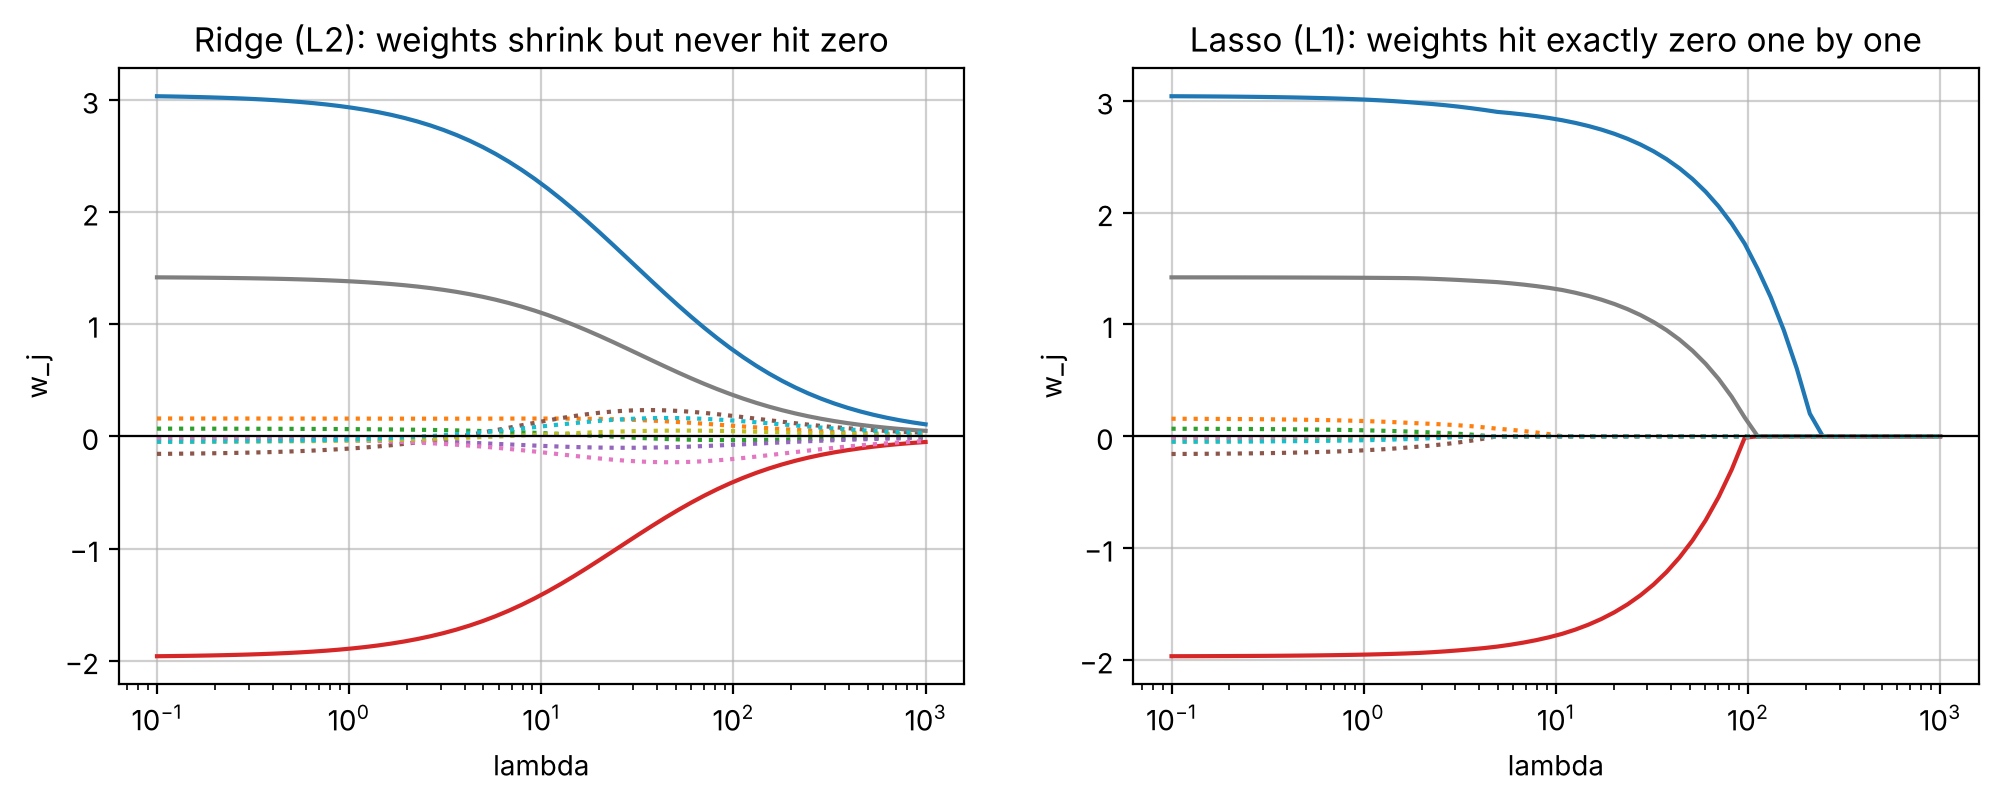

In [8]:
lams = np.logspace(-1, 3, 60)
ridge_path = np.array([ridge(X, y, l) for l in lams])
lasso_path = np.array([lasso(X, y, l) for l in lams])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for j in range(D):
    style = "-" if true_w[j] != 0 else ":"
    axes[0].plot(lams, ridge_path[:, j], style)
    axes[1].plot(lams, lasso_path[:, j], style)

axes[0].set_title("Ridge (L2): weights shrink but never hit zero")
axes[1].set_title("Lasso (L1): weights hit exactly zero one by one")
for ax in axes:
    ax.set_xscale("log")
    ax.set_xlabel("lambda")
    ax.set_ylabel("w_j")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.grid(True, alpha=0.6)

Note: the solid lines are the 3 features that actually matter and the dotted lines are the irrelevant features.

# 4. The Bayesian View of Regularization

## 4.1 MAP Estimation

Using Bayes' rule for the parameters:
$$
\underbrace{p(w|D)}_{\text{Posterior}} \propto \underbrace{p(D|w)}_{\text{Likelihood}} \times \underbrace{p(w)}_{\text{Prior}}
$$
The prior $p(w)$ encodes our beliefs about the parameters before seeing any data. **Maximum a Posteriori (MAP)** estimation finds the parameters that are most probable after observing the data:
$$
w_{MAP} = \arg\max_{w} p(w|D) = \arg\max_{w}\left[\log p(D|w) + \log p(w)\right]
$$
The only difference from MLE is the addition of the log-prior term, $\log p(w)$.

## 4.2 MAP with a Gaussian Prior is Ridge

Let's assume a zero-mean Gaussian prior on the weights:
$$
p(w) = \mathcal{N}(w|0,\tau^2I) \propto \exp\left(-\frac{w^Tw}{2\tau^2}\right)
$$
This prior says we believe the weights are likely to be small and centred around 0. The log-prior is:
$$
\log p(w) = -\frac{1}{2\tau^2}w^Tw + \text{const}
$$

### Proof
The MAP objective becomes (minimising the negative log posterior):
$$
\begin{align*}
w_{MAP} &= \arg\min_{w}\left[-\log p(D|w) - \log p(w)\right] \\
&= \arg\min_{w}\left[\frac{1}{2\sigma^2}\sum_{i=1}^{N}(y_i - w^Tx_i)^2 + \frac{1}{2\tau^2}w^Tw\right] && (\text{using the log-likelihood from 2.2, dropping constants}) \\
&= \arg\min_{w}\left[\sum_{i=1}^{N}(y_i - w^Tx_i)^2 + \frac{\sigma^2}{\tau^2}w^Tw\right] && (\text{multiply by } 2\sigma^2 > 0 \text{, doesn't change the argmin})
\end{align*}
$$
This is exactly the Ridge Regression objective, with $\lambda = \frac{\sigma^2}{\tau^2}$.

**Key Insight:** L2 regularization is equivalent to MAP estimation with a Gaussian prior. A small prior variance $\tau^2$ (strong belief that the weights are small) gives a large $\lambda$.

## 4.3 MAP with a Laplace Prior is Lasso

Now let's assume an independent Laplace prior on each weight, with scale $b$:
$$
p(w) = \prod_{j=1}^{D}\frac{1}{2b}\exp\left(-\frac{|w_j|}{b}\right) \implies \log p(w) = -\frac{1}{b}\sum_{j=1}^{D}|w_j| + \text{const}
$$

### Proof
$$
\begin{align*}
w_{MAP} &= \arg\min_{w}\left[\frac{1}{2\sigma^2}\sum_{i=1}^{N}(y_i - w^Tx_i)^2 + \frac{1}{b}\sum_{j=1}^{D}|w_j|\right] \\
&= \arg\min_{w}\left[\sum_{i=1}^{N}(y_i - w^Tx_i)^2 + \frac{2\sigma^2}{b}\|w\|_1\right] && (\text{multiply by } 2\sigma^2 > 0)
\end{align*}
$$
This is exactly the Lasso objective, with $\lambda = \frac{2\sigma^2}{b}$. So L1 regularization is equivalent to MAP estimation with a Laplace prior.

# 5. Why Does Lasso Create Sparsity?

Recall the Lasso objective:
$$
J_{lasso}(w) = \underbrace{\|y - Xw\|_2^2}_{\text{RSS}} + \underbrace{\lambda\|w\|_1}_{\text{L1 Penalty}}
$$
The L1 penalty encourages many weights $w_j$ to become exactly zero. This is called **sparsity**. We explore three key intuitions for why this happens:
1. The prior interpretation (what L1 corresponds to as a MAP estimate).
2. The analytical mechanism (soft thresholding).
3. The geometric interpretation (via constraint regions).

## 5.1 Explanation 1: The Laplace Prior

Adding a regularizer is MAP estimation under a prior on $w$: Ridge $\leftrightarrow$ a Gaussian prior, and Lasso $\leftrightarrow$ a Laplace prior.

If we give both priors unit variance so the comparison is fair, the Laplace density is more peaked at zero ($0.71$ vs $0.40$) and has heavier tails past $|w_j| \approx 2.4$. The log plot is minus the penalty: a parabola for L2 and a V with a kink for L1.

Peak at zero -> Gaussian: 0.40, Laplace: 0.71


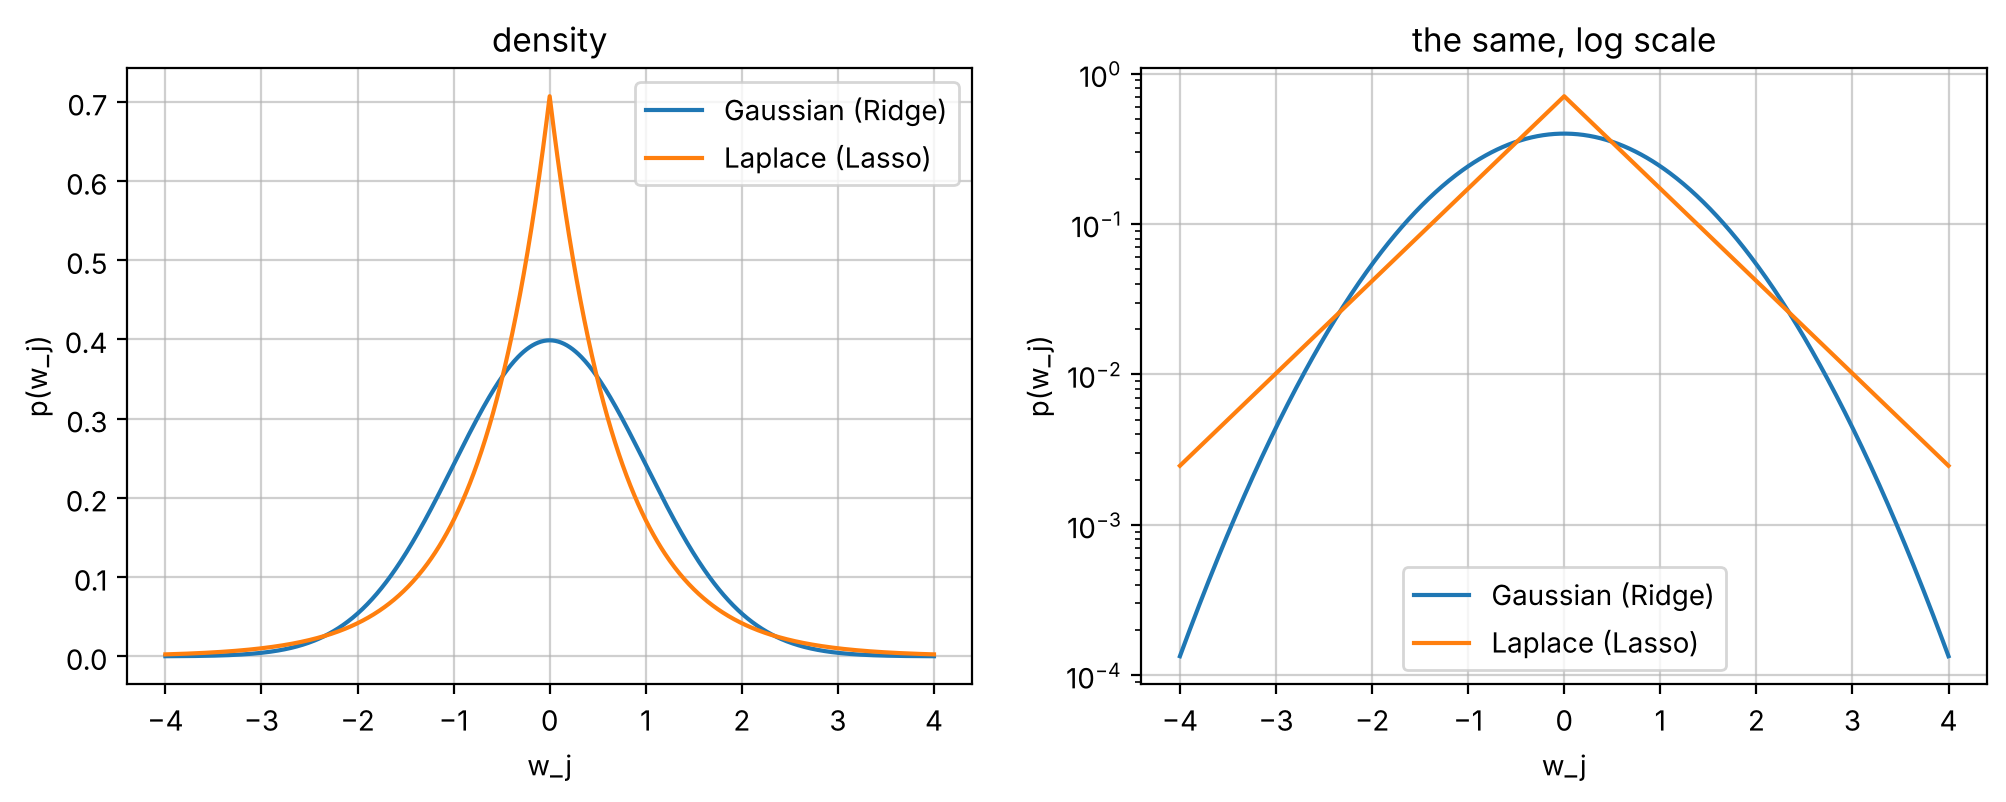

In [9]:
w = np.linspace(-4, 4, 801)

# Gaussian with variance 1
gauss = np.exp(-w**2/2) / np.sqrt(2*np.pi)

# Laplace with variance 2b^2 = 1, so b = 1/sqrt(2)
b = 1/np.sqrt(2)
laplace = np.exp(-np.abs(w)/b) / (2*b)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(w, gauss, label="Gaussian (Ridge)")
axes[0].plot(w, laplace, label="Laplace (Lasso)")
axes[0].set_title("density")

axes[1].plot(w, gauss, label="Gaussian (Ridge)")
axes[1].plot(w, laplace, label="Laplace (Lasso)")
axes[1].set_yscale("log")
axes[1].set_title("the same, log scale")

for ax in axes:
    ax.set_xlabel("w_j")
    ax.set_ylabel("p(w_j)")
    ax.legend()
    ax.grid(True, alpha=0.6)

print(f"Peak at zero -> Gaussian: {gauss.max():.2f}, Laplace: {laplace.max():.2f}")

Note: the Laplace prior still gives zero probability to $w_j = 0$ exactly (it is a continuous density). The exact zeros come from the kink in $|w_j|$, which is explained next.

## 5.2 Explanation 2: Soft Thresholding

To see the mechanism, consider an orthonormal design, $X^TX = I$. Then $\hat{w}^{OLS} = X^Ty$ and the objective decouples:
$$
\begin{align*}
\|y - Xw\|_2^2 + \lambda\Omega(w) &= y^Ty - 2w^TX^Ty + w^TX^TXw + \lambda\Omega(w) \\
&= y^Ty - 2w^T\hat{w}^{OLS} + w^Tw + \lambda\Omega(w) && (\text{since } X^TX = I \text{ and } X^Ty = \hat{w}^{OLS}) \\
&= \|\hat{w}^{OLS} - w\|_2^2 + \lambda\Omega(w) + \text{const} && (\text{complete the square}) \\
&= \sum_{j=1}^{D}\left[(\hat{w}_j^{OLS} - w_j)^2 + \lambda\Omega(w_j)\right] + \text{const}
\end{align*}
$$
So we can solve for each $w_j$ on its own: $\min_{w_j}(\hat{w}_j^{OLS} - w_j)^2 + \lambda\Omega(w_j)$.

### Ridge, $\Omega(w_j) = w_j^2$
$$
\frac{d}{dw_j}\left[(\hat{w}_j^{OLS} - w_j)^2 + \lambda w_j^2\right] = -2(\hat{w}_j^{OLS} - w_j) + 2\lambda w_j = 0 \implies \hat{w}_j = \frac{\hat{w}_j^{OLS}}{1+\lambda}
$$
Ridge shrinks every weight, but never makes it exactly zero.

### Lasso, $\Omega(w_j) = |w_j|$
The derivative of $|w_j|$ is $\text{sign}(w_j)$ when $w_j \neq 0$, so we check each case:
$$
\begin{align*}
w_j > 0: \quad & -2(\hat{w}_j^{OLS} - w_j) + \lambda = 0 \implies w_j = \hat{w}_j^{OLS} - \tfrac{\lambda}{2}, && \text{valid only if } \hat{w}_j^{OLS} > \tfrac{\lambda}{2} \\
w_j < 0: \quad & -2(\hat{w}_j^{OLS} - w_j) - \lambda = 0 \implies w_j = \hat{w}_j^{OLS} + \tfrac{\lambda}{2}, && \text{valid only if } \hat{w}_j^{OLS} < -\tfrac{\lambda}{2} \\
\text{otherwise:} \quad & w_j = 0 && \text{when } |\hat{w}_j^{OLS}| \leq \tfrac{\lambda}{2}
\end{align*}
$$
Putting it all together, we get **soft thresholding** (not required to memorise):
$$
\hat{w}_j = \text{sign}\left(\hat{w}_j^{OLS}\right)\max\left(|\hat{w}_j^{OLS}| - \frac{\lambda}{2}, 0\right)
$$
which is exactly zero once $|\hat{w}_j^{OLS}| \leq \lambda/2$. The flat segment is the sparsity, and it only exists because $|\cdot|$ has a kink at the origin.

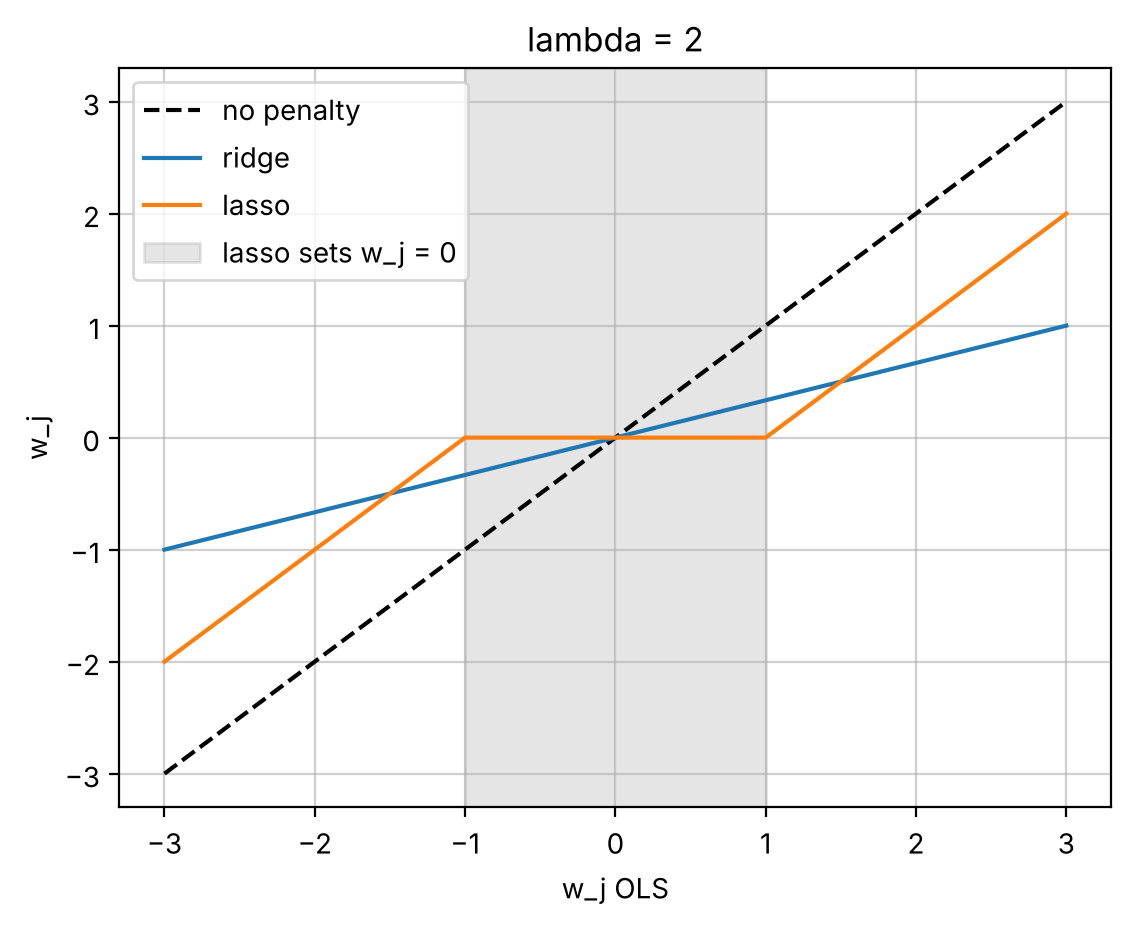

In [10]:
lam = 2
w_ols_grid = np.linspace(-3, 3, 601)

plt.plot(w_ols_grid, w_ols_grid, "k--", label="no penalty")
plt.plot(w_ols_grid, w_ols_grid/(1 + lam), label="ridge")
plt.plot(w_ols_grid, soft_threshold(w_ols_grid, lam/2), label="lasso")
plt.axvspan(-lam/2, lam/2, color="gray", alpha=0.2, label="lasso sets w_j = 0")

plt.xlabel("w_j OLS")
plt.ylabel("w_j")
plt.title(f"lambda = {lam}")
plt.legend()
plt.grid(True, alpha=0.6)

## 5.3 Explanation 3: The Geometric View

Minimising the regularized objective is equivalent to solving a constrained optimization problem:
$$
\min_w \|y - Xw\|_2^2 \quad \text{subject to} \quad \Omega(w) \leq t
$$
The goal is to find the point inside the "constraint region" that is closest to the unconstrained OLS solution (the centre of the RSS ellipses).
* **Ridge (L2):** $\|w\|_2^2 \leq t$, inside a circle $w_1^2 + w_2^2 \leq t$.
* **Lasso (L1):** $\|w\|_1 \leq t$, inside a diamond $|w_1| + |w_2| \leq t$.

The solution is the first point where an expanding RSS contour touches the constraint region. The sharp corners of the L1 diamond make it highly probable that this first point of contact is on an axis (or very close to it), forcing that weight to become exactly zero or very small.

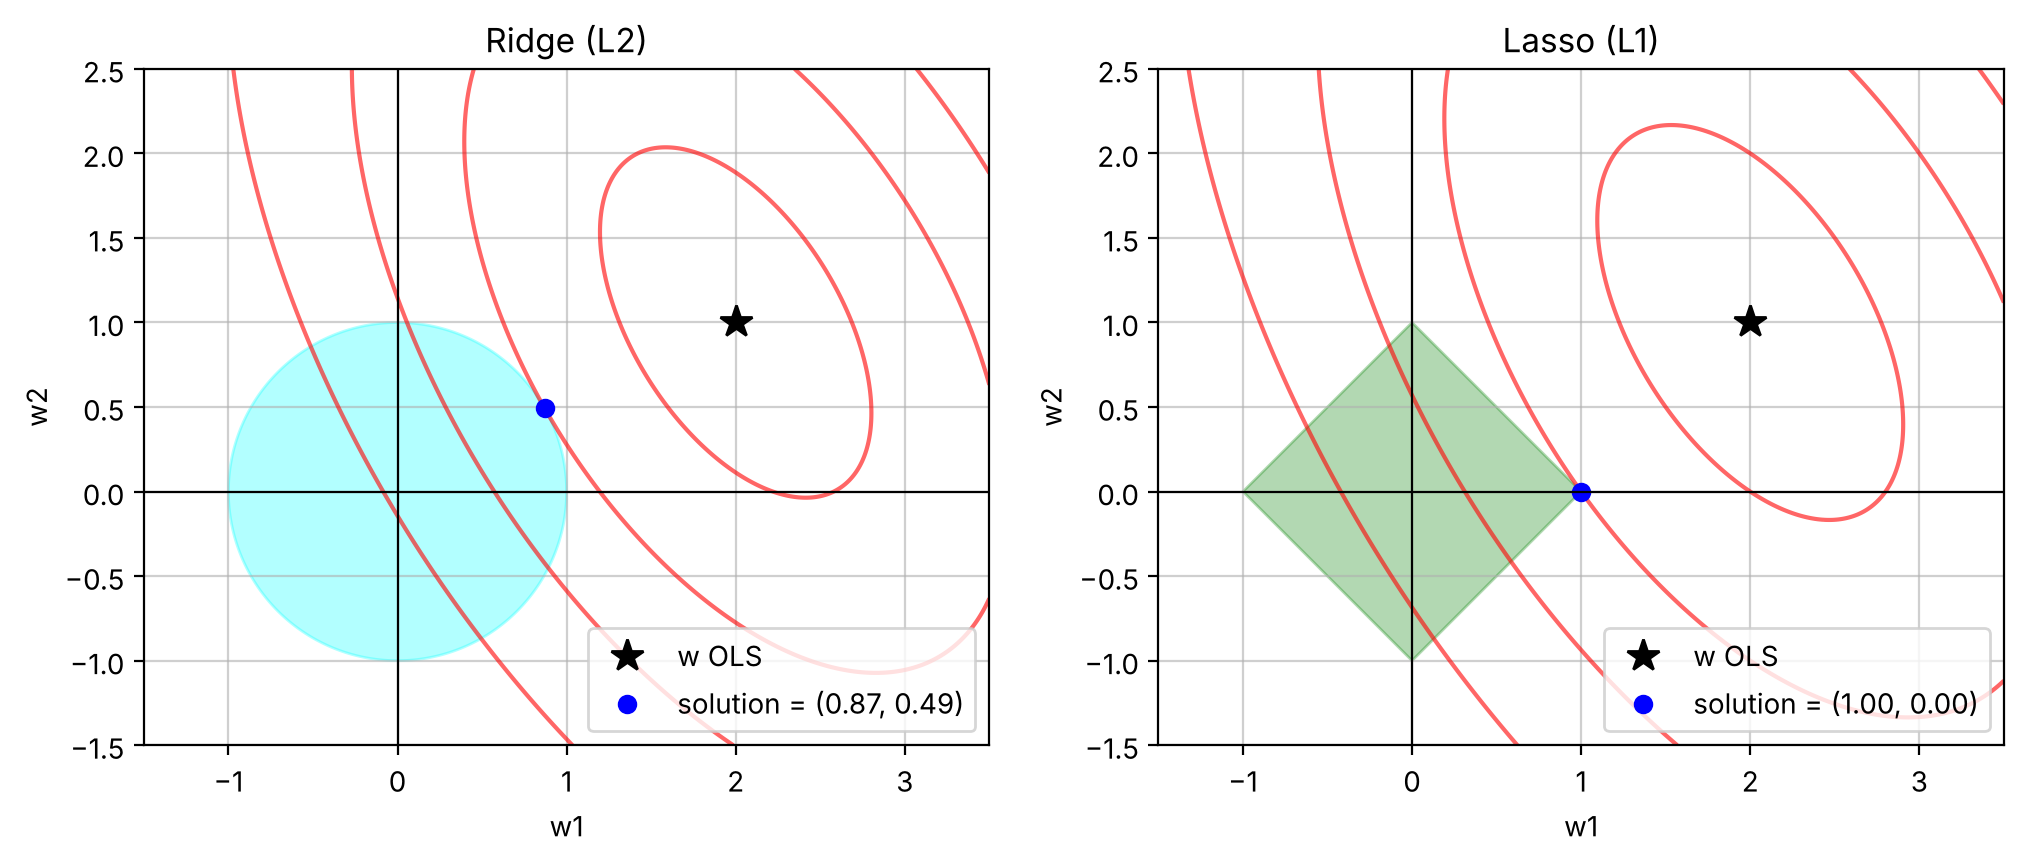

In [11]:
# RSS(w) = (w - w_ols)^T A (w - w_ols) + const, with A = X^T X
w_ols_2d = np.array([2.0, 1.0])
A = np.array([[1.0, 0.4],
              [0.4, 0.6]])
t = 1.0

def rss(w1, w2):
    d1, d2 = w1 - w_ols_2d[0], w2 - w_ols_2d[1]
    return A[0,0]*d1**2 + 2*A[0,1]*d1*d2 + A[1,1]*d2**2

# we find the constrained solution by searching along the boundary of each region
angles = np.linspace(0, 2*np.pi, 20001)
directions = np.column_stack([np.cos(angles), np.sin(angles)])
circle = np.sqrt(t) * directions                                                   # w1^2 + w2^2 = t
diamond = t * directions / (np.abs(directions).sum(axis=1))[:, None]               # |w1| + |w2| = t
w_l2 = circle[np.argmin(rss(circle[:, 0], circle[:, 1]))]
w_l1 = diamond[np.argmin(rss(diamond[:, 0], diamond[:, 1]))]

g1, g2 = np.meshgrid(np.linspace(-1.5, 3.5, 400), np.linspace(-1.5, 2.5, 400))
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, region, w_star, name in [(axes[0], circle, w_l2, "Ridge (L2)"), (axes[1], diamond, w_l1, "Lasso (L1)")]:
    # draw the contour that just touches the region
    level = rss(*w_star)
    ax.contour(g1, g2, rss(g1, g2), levels=[level/4, level, 2*level, 3.5*level], colors="red", alpha=0.6)
    ax.fill(region[:, 0], region[:, 1], color="cyan" if "L2" in name else "green", alpha=0.3)
    ax.plot(*w_ols_2d, "k*", markersize=12, label="w OLS")
    ax.plot(*w_star, "bo", label=f"solution = ({w_star[0]:.2f}, {w_star[1]:.2f})")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(name)
    ax.set_xlabel("w1")
    ax.set_ylabel("w2")
    ax.set_aspect("equal")
    ax.legend(loc="lower right")
    ax.grid(True, alpha=0.6)

We see the L1 solution lands on the corner of the diamond, so $w_2 = 0$ exactly, while the L2 solution keeps both weights non-zero.

## 5.4 A Practical Note: Optimization

The Lasso objective is convex, but $|w_j|$ is **not differentiable** at $w_j = 0$:
$$
J_{lasso}(w) = \|y - Xw\|_2^2 + \lambda\sum_{j=1}^{D}|w_j|
$$
This means we cannot use standard gradient descent, because the gradient is undefined exactly where we expect to find the solution! Instead specialised algorithms are needed. Common approaches include:
* **Subgradient methods:** generalise the concept of a gradient to non-differentiable functions.
* **Coordinate Descent:** optimise the objective for one weight $w_j$ at a time, holding all others fixed. This is very efficient for Lasso (and is what we used in Section 3.4).
* **LARS (Least Angle Regression):** a less common but historically important algorithm.

(This is beyond the scope of this course, but it is important to know that a simple "gradient = 0" approach doesn't work.)

## 5.5 Summary

**Prior / Analytical View**
* L1 penalty $\iff$ MAP under a Laplace prior.
* Next to a Gaussian, it puts more mass near zero with heavier tails, but gives zero probability to $w_j = 0$ exactly.
* The exact zeros come from the kink in $|w_j|$: soft thresholding sets $\hat{w}_j = 0$ once $|\hat{w}_j^{OLS}| \leq \lambda/2$.

**Geometric View**
* The L1 constraint region is a diamond (or hyper-rhombus).
* Its corners lie on the axes, which is the same kink seen from outside.
* The optimal solution is likely to be at one of these corners, forcing some weights to zero.

In practice, lasso performs automatic feature selection: driving irrelevant weights to zero tells us which features matter.

# 6. Model Selection with Cross-Validation

## 6.1 The Hyperparameter Problem

We have introduced a new "knob" to tune: the regularization strength $\lambda$. So how do we choose the best value for $\lambda$? Or more generally, how do we choose between different models (e.g. Ridge vs Lasso, or the polynomial degree)?
* We want the model that performs best on **unseen** data.
* We **cannot** use the test set to choose $\lambda$. This would be "cheating", the test set would no longer be a fair estimate of generalisation performance.

The solution is to create a "pretend" test set: we split our training data into a new, smaller training set and a **validation set**.

## 6.2 K-Fold Cross-Validation

A more robust method than a single validation split is **K-Fold Cross-Validation**. For a single hyperparameter value:
1. Split the training data into $K$ equal-sized folds.
2. For each fold $k = 1,\dots,K$:
    * Treat fold $k$ as the validation set.
    * Train the model on the other $K-1$ folds.
    * Compute the error (e.g. MSE) on the validation fold $k$, call this $E_k$.
3. The cross-validation score is the average error across all folds:
$$
E_{CV} = \frac{1}{K}\sum_{k=1}^{K}E_k
$$

In [12]:
def kfold_cv_mse(X, y, lam, K=5, seed=0):
    # returns the average validation MSE over K folds for ridge regression with strength lam
    N = len(y)
    idx = np.random.default_rng(seed).permutation(N)
    folds = np.array_split(idx, K)
    errors = []
    for k in range(K):
        # fold k is the validation set, the rest is the training set
        val_idx = folds[k]
        train_idx = np.concatenate([folds[i] for i in range(K) if i != k])
        w = ridge(X[train_idx], y[train_idx], lam)
        errors.append(np.mean((y[val_idx] - X[val_idx] @ w)**2))
    return np.mean(errors)

## 6.3 The Full Workflow for Model Selection

1. **Initial Split:** Split all your data into a Training Set and a final Test Set. Lock the test set away.
2. **Hyperparameter Tuning Loop (on the Training Set):**
    * Define a grid of hyperparameters to try (e.g. $\lambda \in \{0.01, 0.1, 1, 10, 100\}$).
    * For each $\lambda$ in the grid, perform K-fold cross-validation and calculate the average validation error $E_{CV}(\lambda)$.
3. **Choose the Best Hyperparameter:** Select the $\lambda^*$ that gives the lowest $E_{CV}$.
4. **Final Training:** Re-train your model on the entire Training Set using $\lambda^*$.
5. **Final Evaluation:** Now, for the first and only time, evaluate your final model on the Test Set. This gives you an unbiased estimate of its generalisation performance.

## 6.4 Polynomial Regression and Overfitting

Regularization also prevents **overfitting**. A model that is too complex fits the noise in the training data, so we add a penalty term to the objective $\mathcal{L}(w;D) + \lambda R(w)$ to discourage model complexity.

A good example of this is **polynomial regression**, a degree-$M$ polynomial in a scalar input $x$:
$$
\hat{y}(x) = w_0 + w_1x + w_2x^2 + \dots + w_Mx^M = \sum_{j=0}^{M}w_jx^j = w^T\phi(x)
$$
with the feature map $\phi(x) = (1, x, x^2, \dots, x^M)^T \in \mathbb{R}^{M+1}$.
* This is still **linear in $w$**, so everything above carries over with $X$ replaced by the design matrix (i.e. handcrafted features) $\Phi \in \mathbb{R}^{N \times (M+1)}$, $\Phi_{ij} = x_i^j$. For ridge regression: $\hat{w}_{ridge} = (\Phi^T\Phi + \lambda I)^{-1}\Phi^Ty$.
* $M$ is the complexity knob: $M = 1$ is a straight line, while a large $M$ can pass close to every noisy point, which demands huge, oscillating coefficients $w_j$.
* That is exactly what L2 or L1 regularization punish.

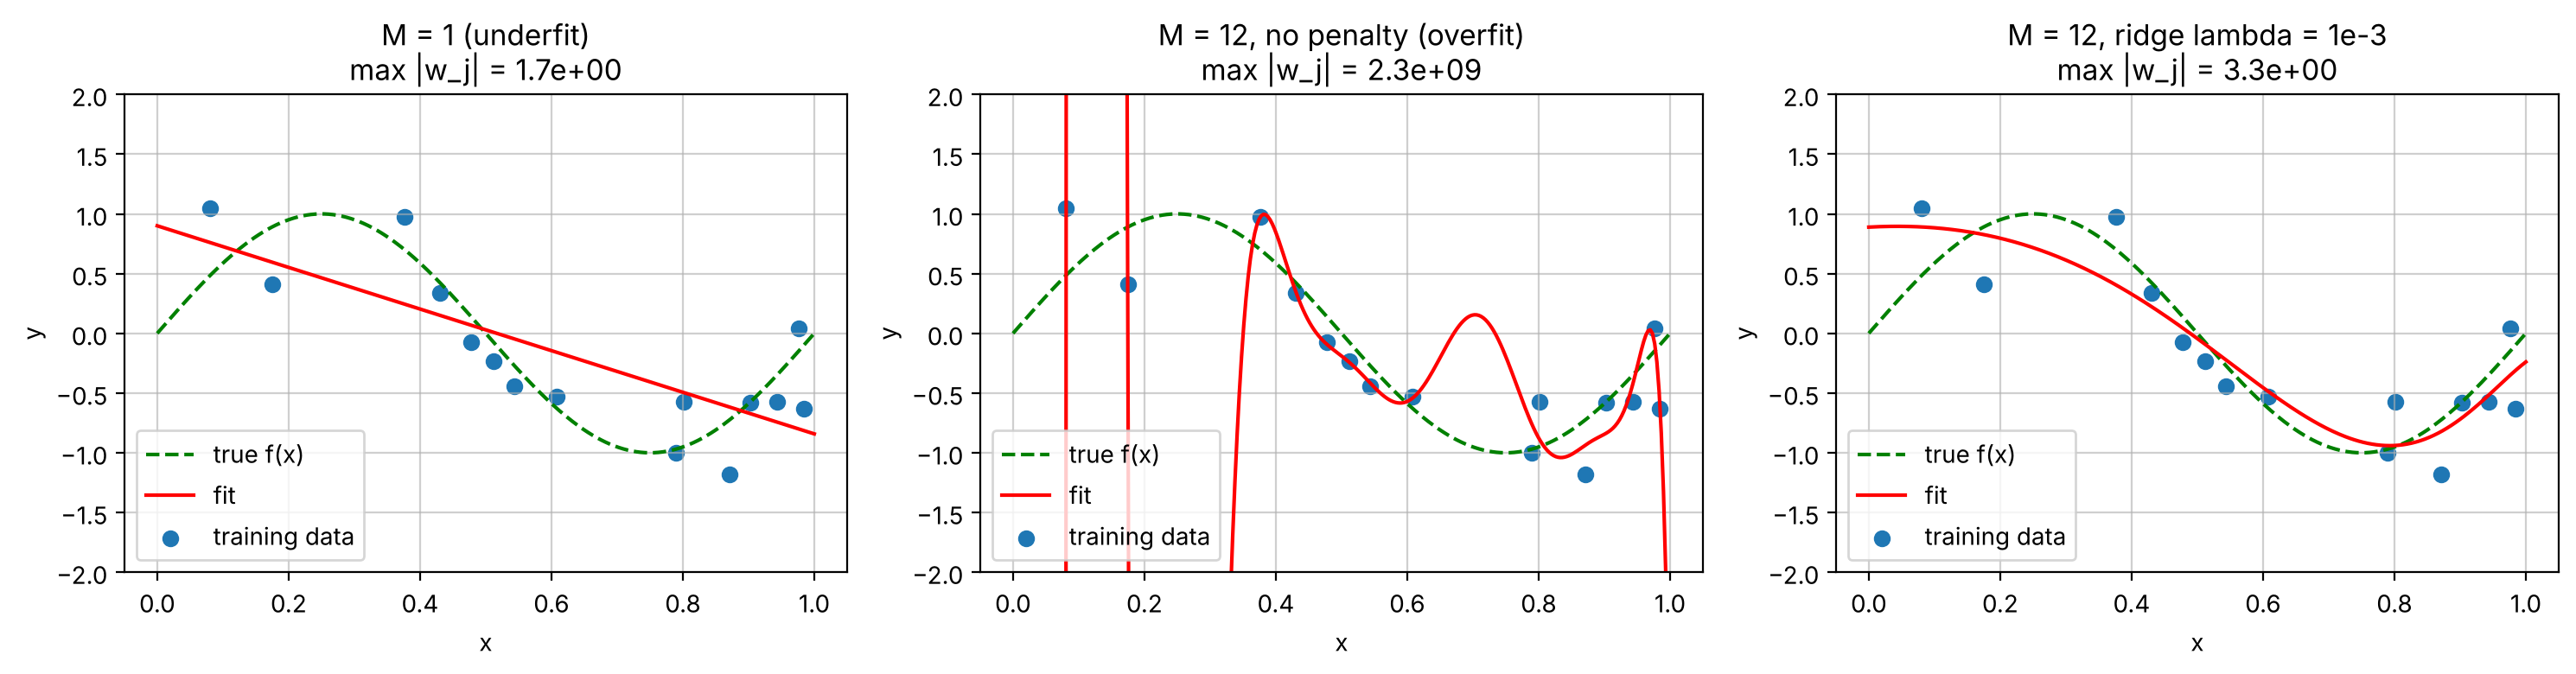

In [13]:
def poly_features(x, M):
    # design matrix Phi with columns 1, x, x^2, ..., x^M
    return np.column_stack([x**j for j in range(M + 1)])

def true_f(x):
    return np.sin(2*np.pi*x)

# first we create a small noisy dataset
rng = np.random.default_rng(4)
N = 15
x_train = np.sort(rng.uniform(0, 1, N))
y_train = true_f(x_train) + rng.normal(0, 0.25, N)
x_plot = np.linspace(0, 1, 300)

# next we fit three models: underfit, overfit and regularized
fits = [
    ("M = 1 (underfit)", 1, 0.0),
    ("M = 12, no penalty (overfit)", 12, 0.0),
    ("M = 12, ridge lambda = 1e-3", 12, 1e-3),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (title, M, lam) in zip(axes, fits):
    Phi = poly_features(x_train, M)
    if lam == 0:
        w = np.linalg.lstsq(Phi, y_train, rcond=None)[0]
    else:
        w = ridge(Phi, y_train, lam)
    ax.plot(x_plot, true_f(x_plot), "g--", label="true f(x)")
    ax.plot(x_plot, poly_features(x_plot, M) @ w, "r", label="fit")
    ax.scatter(x_train, y_train, label="training data")
    ax.set_title(f"{title}\nmax |w_j| = {np.max(np.abs(w)):.1e}")
    ax.set_ylim(-2, 2)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.legend(loc="lower left")
    ax.grid(True, alpha=0.6)
plt.tight_layout()

We see the unregularized $M = 12$ fit has huge coefficients and oscillates wildly, while adding a small ridge penalty keeps the same flexible model smooth.

## 6.5 Choosing $\lambda$ with Cross-Validation in Python

Now we follow the full workflow from Section 6.3 to choose $\lambda$ for the degree $M = 12$ polynomial.

--- Model Selection ---
Best lambda      = 1.00e-05
CV MSE at best   = 0.0408
Final test MSE   = 0.0528  (noise variance = 0.0625)


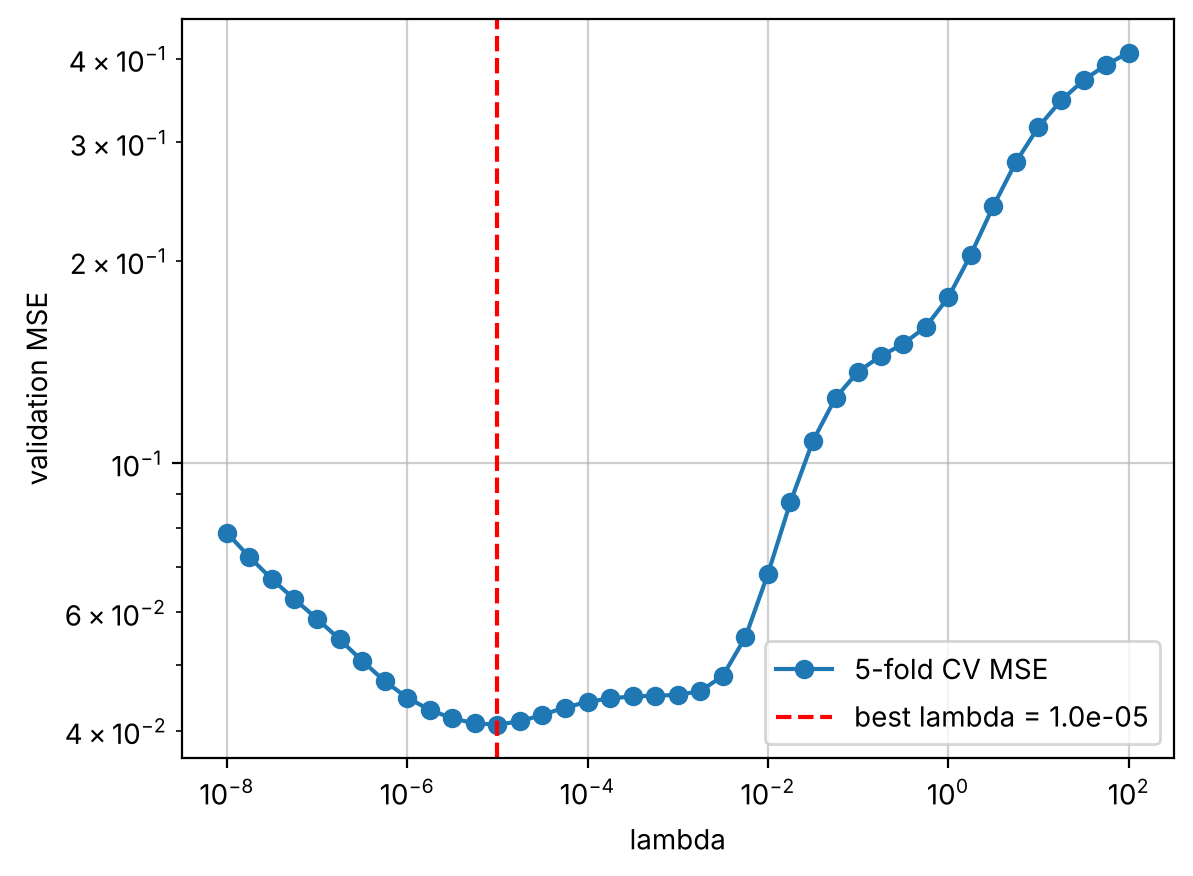

In [14]:
rng = np.random.default_rng(5)
M = 12

# step 1: initial split, generate a dataset and lock the test set away
x_all = rng.uniform(0, 1, 60)
y_all = true_f(x_all) + rng.normal(0, 0.25, 60)
x_tr, y_tr = x_all[:40], y_all[:40]
x_te, y_te = x_all[40:], y_all[40:]
Phi_tr, Phi_te = poly_features(x_tr, M), poly_features(x_te, M)

# step 2: hyperparameter tuning loop with 5-fold CV on the training set only
lam_grid = np.logspace(-8, 2, 41)
cv_scores = np.array([kfold_cv_mse(Phi_tr, y_tr, lam, K=5) for lam in lam_grid])

# step 3: choose the best lambda
best_lam = lam_grid[np.argmin(cv_scores)]

# step 4: re-train on the entire training set
w_final = ridge(Phi_tr, y_tr, best_lam)

# step 5: evaluate on the test set for the first and only time
test_mse = np.mean((y_te - Phi_te @ w_final)**2)

print("--- Model Selection ---")
print(f"Best lambda      = {best_lam:.2e}")
print(f"CV MSE at best   = {cv_scores.min():.4f}")
print(f"Final test MSE   = {test_mse:.4f}  (noise variance = {0.25**2:.4f})")

plt.plot(lam_grid, cv_scores, "o-", label="5-fold CV MSE")
plt.axvline(best_lam, color="red", linestyle="--", label=f"best lambda = {best_lam:.1e}")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("lambda")
plt.ylabel("validation MSE")
plt.legend()
plt.grid(True, alpha=0.6)

On the left (small $\lambda$) the model overfits so the validation error is high, and on the right (large $\lambda$) the model is too simple and underfits. The best $\lambda$ is in between.

# 7. Bias-Variance Tradeoff

The fundamental goal of supervised learning is to learn a model $f(x)$ from training data that makes accurate predictions on new, unseen data. This is the ability to **generalise**. The primary obstacle to good generalisation is prediction error, so what are the sources of this error? And can we break it down to understand it better?

## 7.1 Decomposition of Prediction Error

The expected prediction error of a model at a point $x$ can be decomposed into three fundamental components:
$$
\mathbb{E}\left[(y - \hat{f}(x))^2\right] = \underbrace{\left(\mathbb{E}[\hat{f}(x)] - f(x)\right)^2}_{\text{Bias}^2} + \underbrace{\mathbb{E}\left[\left(\hat{f}(x) - \mathbb{E}[\hat{f}(x)]\right)^2\right]}_{\text{Variance}} + \underbrace{\sigma_\epsilon^2}_{\text{Irreducible Error}}
$$
Where:
$$\begin{align}
    &\hat{f}(x) \text{: is our trained model (it is random, because the training data is random)} \\
    &f(x) \text{: is the true underlying function} \\
    &\sigma_\epsilon^2 \text{: is the inherent noise variance in the data, since } y = f(x) + \epsilon \text{, which we cannot reduce} \\
    &\mathbb{E}[\cdot] \text{: is the expectation over both the training sets and the noise } \epsilon
\end{align}
$$
Our goal is to minimise the two controllable sources of error: Bias and Variance.

### Proof
Let $\bar{f} = \mathbb{E}[\hat{f}(x)]$. The noise $\epsilon$ at the new point has $\mathbb{E}[\epsilon] = 0$, $\mathbb{E}[\epsilon^2] = \sigma_\epsilon^2$, and is independent of $\hat{f}$ (which was trained on different data).
$$
\begin{align*}
\mathbb{E}\left[(y - \hat{f})^2\right] &= \mathbb{E}\left[(f + \epsilon - \hat{f})^2\right] && (\text{since } y = f + \epsilon) \\
&= \mathbb{E}\left[(f - \hat{f})^2\right] + 2\mathbb{E}\left[(f - \hat{f})\epsilon\right] + \mathbb{E}[\epsilon^2] && (\text{expand the square}) \\
&= \mathbb{E}\left[(f - \hat{f})^2\right] + 0 + \sigma_\epsilon^2 && (\text{independence and } \mathbb{E}[\epsilon] = 0) \\
&= \mathbb{E}\left[(f - \bar{f} + \bar{f} - \hat{f})^2\right] + \sigma_\epsilon^2 && (\text{add and subtract } \bar{f}) \\
&= (f - \bar{f})^2 + 2(f - \bar{f})\mathbb{E}\left[\bar{f} - \hat{f}\right] + \mathbb{E}\left[(\bar{f} - \hat{f})^2\right] + \sigma_\epsilon^2 && (f - \bar{f} \text{ is a constant}) \\
&= (f - \bar{f})^2 + 0 + \mathbb{E}\left[(\hat{f} - \bar{f})^2\right] + \sigma_\epsilon^2 && (\text{since } \mathbb{E}[\hat{f}] = \bar{f}) \\
&= \text{Bias}^2 + \text{Variance} + \sigma_\epsilon^2
\end{align*}
$$

## 7.2 What is Bias and Variance?

**Bias** is the systematic error of a model. It measures how far off the average prediction of our model is from the correct value. It is caused by faulty assumptions (e.g. assuming a linear relationship for non-linear data).

**Variance** is the model's sensitivity to the specific training data. It measures how much the model's predictions would change if we trained it on a different training set.
* **High Bias:** The model is consistently wrong in the same direction. It **underfits** the data.
* **High Variance:** The model fits the random noise in the training data instead of the true signal. It **overfits** the data.

## 7.3 The Tradeoff with Model Complexity

Bias and variance are often in opposition to each other.
* **Simple Models** (e.g. Linear Regression) have high bias (strong assumptions) but low variance (they don't change much with new data).
* **Complex Models** (e.g. Deep Decision Trees) have low bias (flexible enough to fit anything) but high variance (they fit the noise, making them very sensitive to the training data).
* The goal of a good model is to find the "sweet spot" that balances the two.

We can see this by simulation: we draw many different training sets from the same $y = \sin(2\pi x) + \epsilon$, fit a polynomial of degree $M$ to each one, and then measure the bias and variance of the fits directly.

In [15]:
rng = np.random.default_rng(6)
noise_sd = 0.3
n_datasets, N = 200, 25
# we keep the inputs x fixed and only redraw the noise, so each training set is a new draw of y
x = np.linspace(0, 1, N)
x_test = np.linspace(0, 1, 100)
degrees = range(0, 11)

def fit_many(M):
    # fit degree M on n_datasets independent training sets, return predictions on x_test
    preds = np.empty((n_datasets, len(x_test)))
    for d in range(n_datasets):
        y = true_f(x) + rng.normal(0, noise_sd, N)
        w = np.linalg.lstsq(poly_features(x, M), y, rcond=None)[0]
        preds[d] = poly_features(x_test, M) @ w
    return preds

bias2, var = [], []
all_preds = {}
for M in degrees:
    preds = fit_many(M)
    all_preds[M] = preds
    f_bar = preds.mean(axis=0)                            # E[f_hat(x)]
    bias2.append(np.mean((f_bar - true_f(x_test))**2))    # averaged over x
    var.append(np.mean(preds.var(axis=0)))                # averaged over x
bias2, var = np.array(bias2), np.array(var)
total = bias2 + var + noise_sd**2

print(f"{'M':<4} {'Bias^2':<10} {'Variance':<10} {'Total':<10}")
print("-" * 34)
for M in degrees:
    print(f"{M:<4} {bias2[M]:<10.4f} {var[M]:<10.4f} {total[M]:<10.4f}")
print(f"\nBest degree = {degrees[np.argmin(total)]}")

M    Bias^2     Variance   Total     
----------------------------------
0    0.4950     0.0039     0.5889    
1    0.2052     0.0074     0.3026    
2    0.2064     0.0100     0.3063    
3    0.0051     0.0132     0.1084    
4    0.0051     0.0167     0.1117    
5    0.0001     0.0183     0.1084    
6    0.0001     0.0229     0.1130    
7    0.0002     0.0286     0.1187    
8    0.0002     0.0301     0.1203    
9    0.0002     0.0324     0.1227    
10   0.0001     0.0361     0.1262    

Best degree = 5


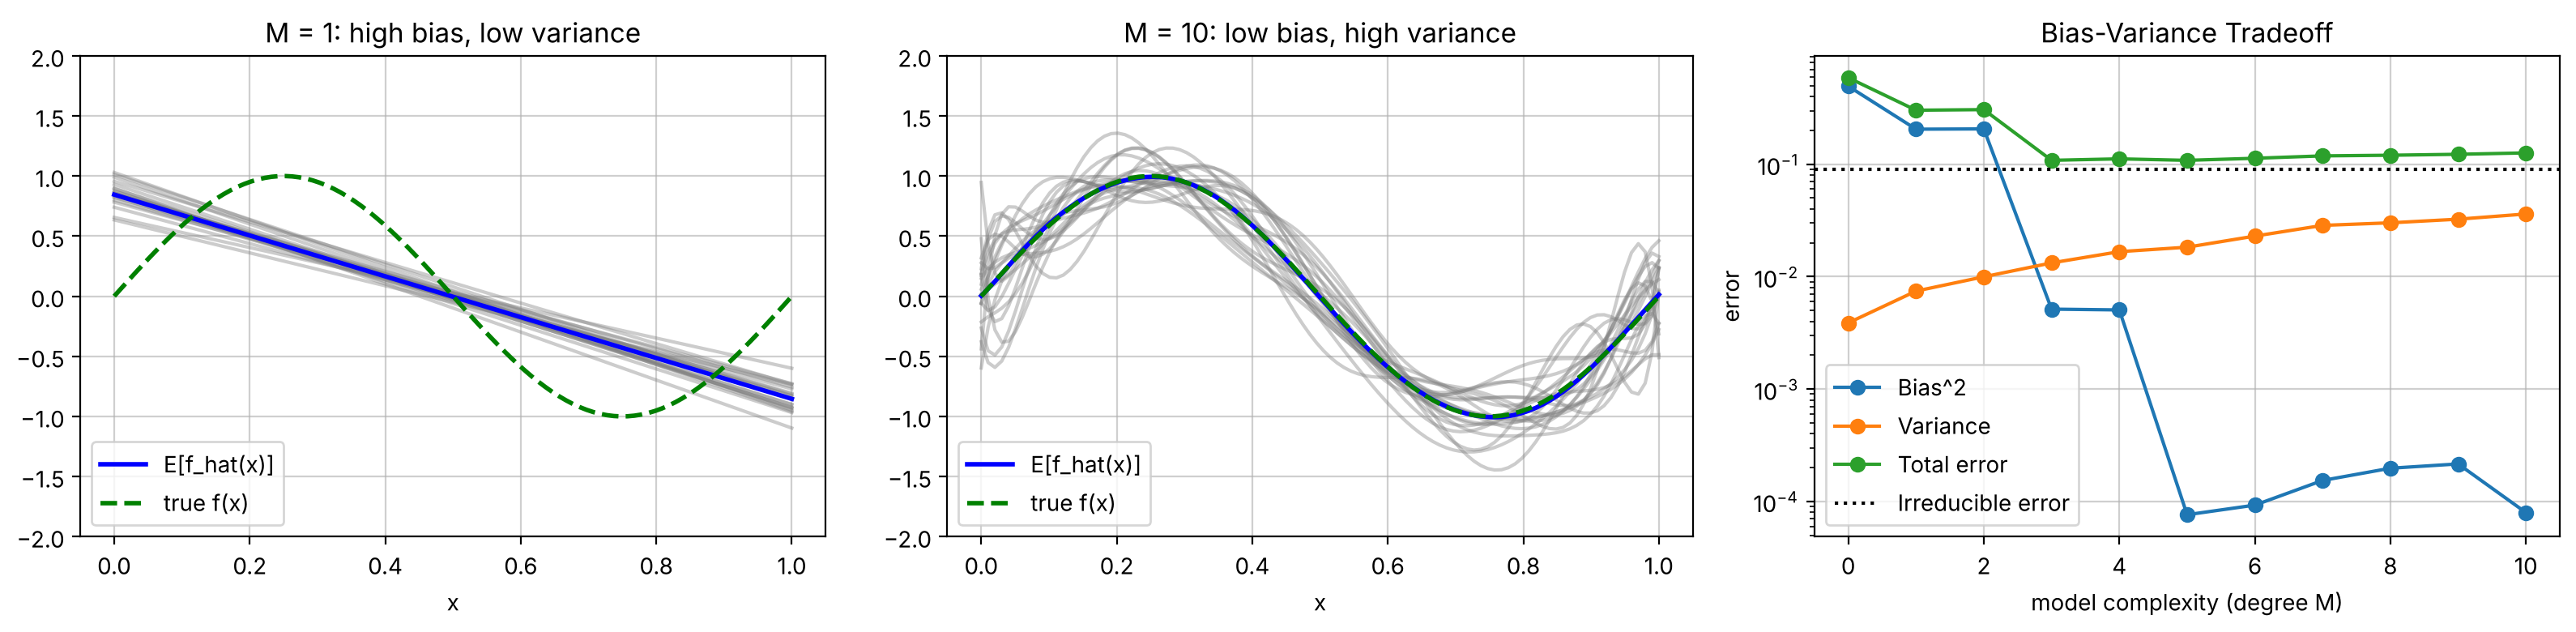

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# left and middle: 20 of the fitted models for a simple and a complex model
for ax, M in [(axes[0], 1), (axes[1], 10)]:
    for d in range(20):
        ax.plot(x_test, all_preds[M][d], color="gray", alpha=0.4)
    ax.plot(x_test, all_preds[M].mean(axis=0), "b", linewidth=2, label="E[f_hat(x)]")
    ax.plot(x_test, true_f(x_test), "g--", linewidth=2, label="true f(x)")
    ax.set_title(f"M = {M}: " + ("high bias, low variance" if M == 1 else "low bias, high variance"))
    ax.set_ylim(-2, 2)
    ax.set_xlabel("x")
    ax.legend(loc="lower left")
    ax.grid(True, alpha=0.6)

# right: the tradeoff w.r.t. model complexity
axes[2].plot(degrees, bias2, "o-", label="Bias^2")
axes[2].plot(degrees, var, "o-", label="Variance")
axes[2].plot(degrees, total, "o-", label="Total error")
axes[2].axhline(noise_sd**2, color="black", linestyle=":", label="Irreducible error")
axes[2].set_yscale("log")
axes[2].set_xlabel("model complexity (degree M)")
axes[2].set_ylabel("error")
axes[2].set_title("Bias-Variance Tradeoff")
axes[2].legend()
axes[2].grid(True, alpha=0.6)
plt.tight_layout()

## 7.4 Summary

* Prediction error can be broken down into **Bias**, **Variance**, and **Irreducible Error**.
* Bias is systematic error from wrong model assumptions (underfitting).
* Variance is error from sensitivity to the training data (overfitting).
* There is a fundamental tradeoff: decreasing one often increases the other.
* The goal of building a good machine learning model is to find the right level of model complexity to achieve the lowest possible total error on unseen data.

Note: Regularization (Section 3) is one way to move along this tradeoff, increasing $\lambda$ adds a little bias but can greatly reduce the variance.